<a href="https://colab.research.google.com/github/Virna-Valentina/Entregables-Virna-Rodriguez/blob/main/Taller_4_Aprendizaje_no_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TALLER PRÁCTICO – APRENDIZAJE  NO SUPERVISADO**

Instrucciones
Trabaja sobre el dataset suministrado y desarrolla un análisis completo que incluya las siguientes etapas:
df = https://www.kaggle.com/datasets/tamber/steam-video-games

Exploración de los datos
Realiza un análisis exploratorio del conjunto de datos que incluya:

    • Dimensiones del dataset.
    • Tipos de variables.
    • Valores nulos.
    • Registros duplicados.
    • Estadísticos descriptivos.
    • Visualizaciones que permitan comprender la información.


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tamber/steam-video-games")

print("Path to dataset files:", path)

100%|██████████| 1.46M/1.46M [00:00<00:00, 113MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/tamber/steam-video-games/versions/3


In [7]:
import os
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [16]:
csv_path = os.path.join(path, "steam-200k.csv")
df = pd.read_csv(csv_path, header=None, names= ["user_id", "game_name", "behavior", "value", "other"])

In [17]:
df.head()

,user_id,game_name,behavior,value,other
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [18]:
df.shape

(200000, 5)

In [19]:
df.describe()

,user_id,value,other
count,2.000000e+05,200000.000000,200000.0
mean,1.036559e+08,17.874384,0.0
std,7.208074e+07,138.056952,0.0
min,5.250000e+03,0.100000,0.0
25%,4.738420e+07,1.000000,0.0
50%,8.691201e+07,1.000000,0.0
75%,1.542309e+08,1.300000,0.0
max,3.099031e+08,11754.000000,0.0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   user_id    200000 non-null  int64  
 1   game_name  200000 non-null  object 
 2   behavior   200000 non-null  object 
 3   hours      200000 non-null  float64
 4   other      200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [20]:
df.isnull().sum()

,0
user_id,0
game_name,0
behavior,0
value,0
other,0


In [24]:
df['behavior'].unique()

array(['purchase', 'play'], dtype=object)

In [26]:
df['game_name'].unique()

array(['The Elder Scrolls V Skyrim', 'Fallout 4', 'Spore', ...,
       'Space Colony', 'Life is Hard', 'Executive Assault'],
      shape=(5155,), dtype=object)

In [21]:
# Al evidenciar que no hay valores distintos que representan los mismos regristos procedemos a analizar los duplicados
df.duplicated().sum()


np.int64(707)

In [22]:
df[df.duplicated(keep=False)]

,user_id,game_name,behavior,value,other
1787,11373749,Sid Meier's Civilization IV,purchase,1.0,0
1968,11373749,Sid Meier's Civilization IV,purchase,1.0,0
1969,11373749,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
1970,11373749,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
1971,11373749,Sid Meier's Civilization IV Warlords,purchase,1.0,0
...,...,...,...,...,...
195815,112845094,Grand Theft Auto III,purchase,1.0,0
195821,112845094,Grand Theft Auto San Andreas,purchase,1.0,0
195822,112845094,Grand Theft Auto Vice City,purchase,1.0,0
195823,112845094,Grand Theft Auto Vice City,purchase,1.0,0


In [23]:
#Teniendo en cuenta que si se evidencian duplicados,
#analizaremos los duplicados con una llave, ya que un usuario deberia maximo una fila como compra y una de juego.

llave = ["user_id", "game_name", "behavior"]
df.duplicated(subset=llave).sum()
df[df.duplicated(subset=llave, keep=False)].sort_values(llave)

,user_id,game_name,behavior,value,other
142904,561758,Sid Meier's Civilization IV,purchase,1.0,0
142905,561758,Sid Meier's Civilization IV,purchase,1.0,0
142906,561758,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
142907,561758,Sid Meier's Civilization IV Beyond the Sword,purchase,1.0,0
142908,561758,Sid Meier's Civilization IV Colonization,purchase,1.0,0
...,...,...,...,...,...
20237,267053376,Grand Theft Auto San Andreas,purchase,1.0,0
61071,302237901,Grand Theft Auto San Andreas,purchase,1.0,0
61074,302237901,Grand Theft Auto San Andreas,purchase,1.0,0
22541,305835588,Grand Theft Auto San Andreas,purchase,1.0,0


In [27]:
#Identificamos duplicados exactos
def reporte_duplicados(df, llave=None):
    print("Filas totales:", len(df))
    print("Duplicados exactos:", df.duplicated().sum())
    if llave:
        print(f"Duplicados por {llave}:", df.duplicated(subset=llave).sum())

reporte_duplicados(df, llave=["user_id", "game_name", "behavior"])

Filas totales: 200000
Duplicados exactos: 707
Duplicados por ['user_id', 'game_name', 'behavior']: 719


In [28]:
#Ordeno y elimino duplicados, conservando el maximo en horas para Juego
df_ord = df.sort_values("value", ascending=False)

es_dup_play = (df_ord["behavior"] == "play") & df_ord.duplicated(subset=llave, keep="first")
df_limpio = df_ord[~es_dup_play].sort_index()



In [29]:
#evidenciamos que ya no hay duplicados teniendo en cuenta juego
df_limpio[df_limpio["behavior"] == "play"].duplicated(subset=llave).sum()   # → 0

np.int64(0)

In [31]:
#Ordeno y elimino duplicados, conservando el primero de compra

df_ord = df.sort_values("value", ascending=False)

es_dup_play = (df_ord["behavior"] == "purchase") & df_ord.duplicated(subset=llave, keep="first")
df_limpio = df_ord[~es_dup_play].sort_index()

In [32]:
df_limpio[df_limpio["behavior"] == "purchase"].duplicated(subset=llave).sum()   # → 0

np.int64(0)

In [35]:
df_limpio.duplicated().sum()

np.int64(0)

In [39]:
#Corroboramos que los duplicados fueron eliminados exitosamente
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199293 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   user_id    199293 non-null  int64  
 1   game_name  199293 non-null  object 
 2   behavior   199293 non-null  object 
 3   value      199293 non-null  float64
 4   other      199293 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 13.2+ MB


In [50]:
df_play = df_limpio[df_limpio["behavior"] == "play"]
df_play.shape


(70489, 5)

In [51]:
df_purc = df_limpio[df_limpio["behavior"] == "purchase"]
df_purc.shape


(128804, 5)

**Estadisticas**

Con la siguiente tabla podemos analizar la cantidad de jugadores que juega cada juego,


*   Podemos analizar el total de horas de juego, el promedio, la mediana y el maximo de horas jugadas
*   Dota 2 es el juego mas jugado teniendo en cuenta horas totales, sin embargo, no es uno de los que mas tiempo juegan en promedio.
*   Eastside Hockey Manager es el juego con mayor cantidad de horas en promedio jugadas, sin embargo, esto se da porque solo 1 jugador lo juega.
*   Sid Meier's Civilization V es el juego que más cantidad de horas maximas se ha jugado Sid 11.754
*   En el top 20, se puede evidenciar un patron sobre los juegos que retienen a los jugadores mayor cantidad de tiempo, los simuladores de juegos deportivos, footbal, hookey, FIFA y Baseball



In [92]:

resumen = (
    df_limpio[df_limpio["behavior"] == "play"]
    .groupby("game_name")["value"]
    .agg(jugadores="count", total="sum" ,promedio="mean", mediana="median", maximo="max")
    .round(1)
    .sort_values("jugadores", ascending=False)
)

resumen.head(20)

,jugadores,total,promedio,mediana,maximo
game_name,,,,,
Dota 2,4841,981684.6,202.8,5.5,10442.0
Team Fortress 2,2323,173673.3,74.8,4.4,9640.0
Counter-Strike Global Offensive,1377,322771.6,234.4,61.0,4659.0
Unturned,1069,16096.4,15.1,3.5,850.0
Left 4 Dead 2,801,33596.7,41.9,10.5,2710.0
Counter-Strike Source,715,96075.5,134.4,13.8,4676.0
The Elder Scrolls V Skyrim,677,70889.3,104.7,47.0,1986.0
Garry's Mod,666,49725.3,74.7,17.2,3667.0
Counter-Strike,568,134261.1,236.4,8.8,4814.0


*Graficos*

 **Cantidad de Registros por Tipo de Comportamiento**

Se evidencia que son más la cantidad de compras que las horas de juego, lo que indica que hay muchas personas que compran y no juegan el juego comprado. Cerca del 45% de los juegos no se jugó.

**Top 10 Videojuegos más Jugados (Horas promedio)**
Al igual que en la tabla anterior se evidencia el patrón de genero, los tipos de juego que retienen más a los jugadores son los que simulan juegos deportivos.

En la tabla anterior veiamos a juegos como Dota 2, Team fortress 2 y
Counter-Strike Global Offensive en el top 2, sin embargo si revisamos horas de juego promedio no salen ni en el top 3.

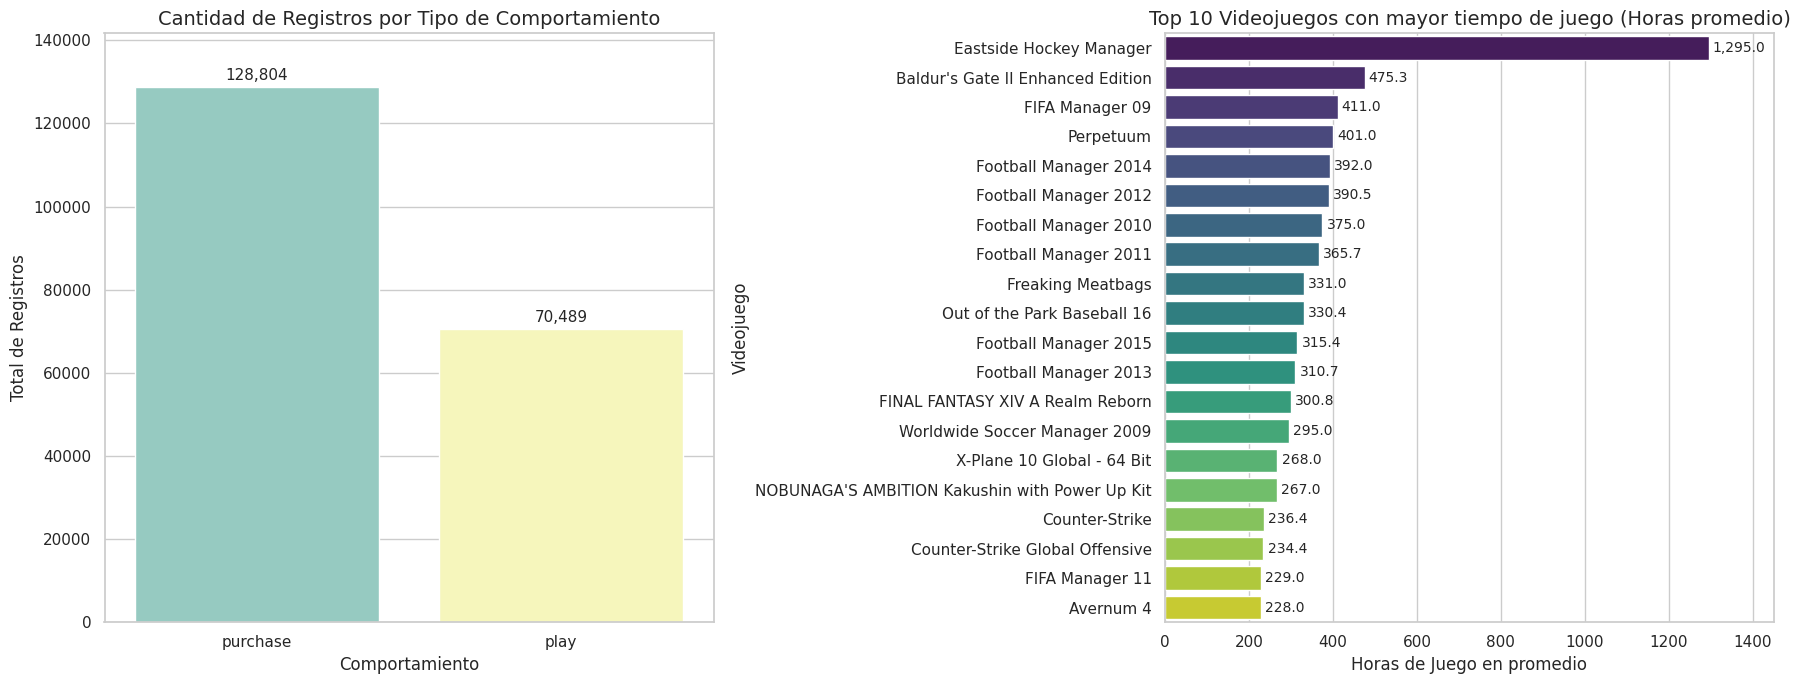

In [91]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Izquierda: comprar vs jugar
sns.countplot(data=df_limpio, x="behavior", ax=axes[0], palette="Set3", hue="behavior", legend=False)
axes[0].set_title("Cantidad de Registros por Tipo de Comportamiento", fontsize=14)
axes[0].set_xlabel("Comportamiento", fontsize=12)
axes[0].set_ylabel("Total de Registros", fontsize=12)

for contenedor in axes[0].containers:
    axes[0].bar_label(contenedor, fmt="{:,.0f}", padding=3, fontsize=11)
axes[0].margins(y=0.1)   # espacio arriba para que la etiqueta no se corte

# Derecha: top 10 por horas promedio
top_hours_games = df_play.groupby("game_name")["value"].mean().sort_values(ascending=False).head(20)
sns.barplot(x=top_hours_games.values, y=top_hours_games.index, ax=axes[1],
            palette="viridis", hue=top_hours_games.index, legend=False)
axes[1].set_title("Top 10 Videojuegos con mayor tiempo de juego (Horas promedio)", fontsize=14)
axes[1].set_xlabel("Horas de Juego en promedio", fontsize=12)
axes[1].set_ylabel("Videojuego", fontsize=12)

for contenedor in axes[1].containers:
    axes[1].bar_label(contenedor, fmt="{:,.1f}", padding=3, fontsize=10)
axes[1].margins(x=0.12)  # espacio a la derecha para las etiquetas

plt.tight_layout()
plt.show()

**Preparación de los datos**

Realiza el preprocesamiento necesario para aplicar técnicas de clustering.
Debes justificar cada decisión tomada.

**Modelado**

Implementa un algoritmo de clustering, por ejemplo:

    • K-Means
    • DBSCAN
    • Clustering Jerárquico
Justifica la elección de los algoritmos utilizados.


*La razón principal por la que elegí Kmens es por el tamaño de la base, con jerarquia sería un poco más lento, y por la facilidad con la que se manejan las herramientas para justificar el número de grupos.*

*Al concatenar los grupos con las metricas, podemos evidenciar que hay usuarios que compran juegos y no juegan nada, o que compran varios juegos pero solo juegan una pequeña cantidad*

In [94]:
# Primero defino qué voy a agrupar, agruparé compras y juego
import numpy as np

compras = (df_limpio[df_limpio["behavior"] == "purchase"]
           .groupby("user_id")["game_name"].nunique()
           .rename("juegos_comprados"))

juego = (df_limpio[df_limpio["behavior"] == "play"]
         .groupby("user_id")["value"]
         .agg(juegos_jugados="count",
              horas_totales="sum",
              horas_promedio="mean",
              horas_max="max"))

usuarios = pd.concat([compras, juego], axis=1).fillna(0)

# Identifico qué proporción de lo que compró realmente lo jugó
usuarios["pct_jugado"] = (usuarios["juegos_jugados"] / usuarios["juegos_comprados"]).clip(upper=1).fillna(0)

# Identifico qué tan concentrado está en un solo juego (1 = juega casi solo uno)
usuarios["concentracion"] = (usuarios["horas_max"] / usuarios["horas_totales"]).fillna(0)

usuarios.head(20)

,juegos_comprados,juegos_jugados,horas_totales,horas_promedio,horas_max,pct_jugado,concentracion
user_id,,,,,,,
5250,21,6.0,225.5,37.583333,144.0,0.285714,0.638581
76767,36,20.0,1227.0,61.350000,365.0,0.555556,0.297474
86540,82,15.0,255.0,17.000000,113.0,0.182927,0.443137
103360,10,0.0,0.0,0.000000,0.0,0.000000,0.000000
144736,8,1.0,0.1,0.100000,0.1,0.125000,1.000000
181212,12,2.0,2.2,1.100000,1.8,0.166667,0.818182
229911,27,18.0,390.5,21.694444,165.0,0.666667,0.422535
298950,259,175.0,3745.4,21.402286,1019.0,0.675676,0.272067
299153,14,0.0,0.0,0.000000,0.0,0.000000,0.000000


*Aplicamos trasformación logaritmica para estabilizar el sesgo extremo, esto porque las horas y la cantidad de juegos están muy sesgadas*

In [71]:
cols_log = ["juegos_comprados", "juegos_jugados", "horas_totales", "horas_promedio", "horas_max"]
X = usuarios.copy()
X[cols_log] = np.log1p(X[cols_log])   # log(1 + x), funciona con ceros

In [72]:
from sklearn.preprocessing import StandardScaler

features = ["juegos_comprados", "juegos_jugados", "horas_totales",
            "horas_promedio", "pct_jugado", "concentracion"]

X_scaled = StandardScaler().fit_transform(X[features])

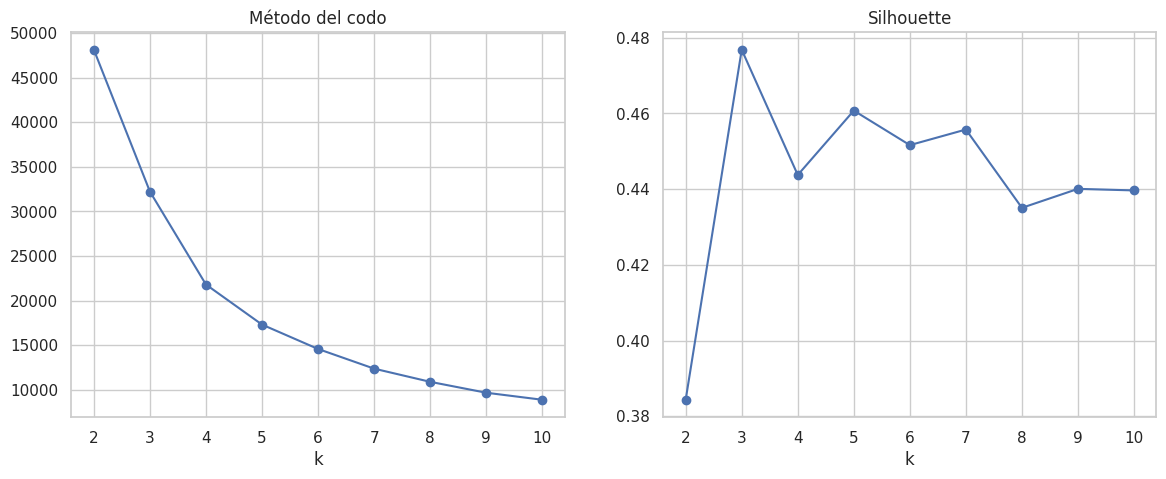

In [73]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inercias, siluetas = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(ks, inercias, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k")
ax[1].plot(ks, siluetas, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.show()

*Basado en el resultado de las gráficas elijo K=4 para entrenar el modelo, porque es donde se quiebra la curva de inercia*

In [77]:
k = 4
km = KMeans(n_clusters=k, n_init=10, random_state=42)
usuarios["cluster"] = km.fit_predict(X_scaled)

usuarios["cluster"].value_counts().sort_index()

,count
cluster,
0,5879
1,1061
2,3431
3,2022


**Interpretación de los clusters**

Describe cada uno de los grupos encontrados.
Puedes responder preguntas como:

    • Qué caracteriza a los usuarios de este grupo?
    • Son jugadores ocasionales o frecuentes?
    • Presentan comportamientos similares de compra?
    • Qué diferencias existen entre los clusters?

Asigna un nombre representativo a cada segmento.

Ejemplo:

    • Jugadores Casual
    • Coleccionistas
    • Usuarios Muy Activos
    • Compradores Frecuentes

**Perfilamiento de clusters**

**Cluster 0** = Jugadores Casual 47%

*Son usuarios que tienen un volumnen muy bajo de compra y un tiempo promedio bajo de juego, se tienen 5.879 usuarios en este Cluster.*

**Cluster 1** = Compradores sin activar 9%

*Son usuarios que tienen un volumnen bajo de compra y un tiempo promedio nulo de juego, compraron pero no juegan , se tienen 1.061 usuarios en este Cluster.*

**Cluster 2** = Jugadores Activos sin compra recurrente 28%

*Son usuarios que tienen un volumnen pequeño de compra y un tiempo promedio alto de juego, son fieles al juego , se tienen 3.431 usuarios en este Cluster.*

**Cluster 3** = Jugadores Multijuego 16%

*Son usuarios que tienen un volumnen alto de compra y un tiempo promedio alto de juego, muchas horas en muchos juegos , se tienen 2.022 usuarios en este Cluster.*


La diferencia radica en el volumen de compra y las horas promedio de juego

In [78]:
perfil = usuarios.groupby("cluster")[features + ["horas_max"]].median().round(2)
perfil["usuarios"] = usuarios["cluster"].value_counts()
perfil

,juegos_comprados,juegos_jugados,horas_totales,horas_promedio,pct_jugado,concentracion,horas_max,usuarios
cluster,,,,,,,,
0,1.0,1.0,2.5,2.10,1.00,1.00,2.4,5879
1,1.0,0.0,0.0,0.00,0.00,0.00,0.0,1061
2,3.0,1.0,130.0,77.20,1.00,1.00,116.0,3431
3,25.0,15.0,525.0,25.85,0.67,0.43,204.5,2022



**Recomendaciones de negocio**
Con base en los segmentos encontrados, responde:


    • 1. Qué estrategia de marketing implementarías para cada grupo?
    • 2. Qué tipo de promociones recibiría cada segmento?
    • 3. Qué usuarios priorizarías para campañas de fidelización?
    * 4. Qué información adicional sería útil para mejorar la segmentación?

**Estrategia de marketing**

Cluster 0 – Abandonaron rápido, así que el objetivo es lograr una segunda experiencia positiva y convertirlos en jugadores recurrentes.

Cluster 1 – El objetivo es que jueguen por primera vez, porque un usuario que nunca juega difícilmente vuelve a comprar.

Cluster 2 – el objetivo es ampliar su interés a otros títulos para reducir su dependencia de un solo juego.

Cluster 3 – Son los más valiosos; el objetivo es mantenerlos y que sigan comprando.

**Promociones**

Cluster 0 - descuentos en un segundo juego.

Cluster 1 - recompensas o logros por la primera sesión.

Cluster 2 - recomendaciones con descuento de juegos similares.

Cluster 3 - programa de lealtad con puntos.

**Prioridad para campañas de fidelización**

 Cluster 3 - Jugadores multijuego, son los usuarios con mayor valor, por su volumne de compra y por horas de juego y perderlos tendria un impacto muy grande.

 **Información Util para la segmentación**

 Género o categoría de cada juego

 Datos demograficos del usuario

 Esto para recomendar según gustos de los usuarios, y para personalizar recomendaciones.
